# 07 — Evolución temporal de la composición de participantes

**Etapa CRISP-DM:** Análisis / evaluación · **OE4 / OE5**

## Objetivo
Producir los **artefactos del informe LaTeX** (figuras PNG, tablas CSV y `.tex`)
sobre cómo ha **evolucionado la composición de los participantes** en
internacionalización a lo largo de los años, usando **el mismo cálculo** que
alimenta el dashboard (`src.historical_stats.compute_historical`). Este notebook
**no recalcula** estadística: la lee de `hist` y solo **dibuja, tabula, narra y
verifica**.

## Principios y encuadre
- **Fuente única de verdad (RNF-1):** las cifras del informe salen del mismo dict
  que `data.json`. El redondeo se aplica una sola vez en Python (dict
  `historical_stats.DECIMALES`).
- **Composición, no proporción de participación por grupo.** La única variable
  temporal fina a nivel estudiante es `PRIMER_ANIO_MOVILIDAD` y **solo existe para
  participantes**; no hay denominador temporal. Por eso todo se lee como
  *composición de los participantes de cada año* o *media por año*, y **nunca**
  como proporción de participación respecto de la población.
- **Asociación, no causa.** Los cambios de composición son patrones observados.
- **Privacidad (RNF-3):** solo agregados; años con $n < 30$ suprimidos; se recorta
  la cola rala anterior a 2012.
- **Consistencia verificada (M1):** la última celda **falla el build** si las
  cifras renderizadas (CSV/.tex) divergen de `hist` o de `data.json`.

In [1]:
import sys, os
from pathlib import Path
# Permitir importar el paquete src desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 12

from src import config, utils, internationalization as intl
print('Entorno listo. Raiz del proyecto:', ROOT)

Entorno listo. Raiz del proyecto: C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO


In [2]:
# Dependencias específicas del notebook: cálculo (fuente única) y formateo LaTeX.
import shutil
import json
import csv
from src import historical_stats as hs
from nb_helpers import df_to_latex_booktabs

# Rutas ABSOLUTAS desde config (el kernel corre con cwd=notebooks/).
LATEX_DIR = config.ROOT_DIR / 'latex'
LATEX_TABLAS = LATEX_DIR / 'tablas'
LATEX_FIG = LATEX_DIR / 'figuras'
LATEX_TABLAS.mkdir(parents=True, exist_ok=True)
LATEX_FIG.mkdir(parents=True, exist_ok=True)
DATA_JSON = config.ROOT_DIR / 'dashboard' / 'public' / 'data.json'
print('Tablas .tex ->', LATEX_TABLAS)
print('Figuras     ->', LATEX_FIG)

Tablas .tex -> C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO\latex\tablas
Figuras     -> C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO\latex\figuras


## 1. Cálculo histórico (fuente única)
Se carga el dataset analítico y se llama a `compute_historical` **una sola vez**.
El dict `hist` es idéntico al que `export_dashboard` escribe bajo la clave
`historico` de `data.json`.

In [3]:
df = pd.read_parquet(config.ANALYTIC_DATASET)
hist = hs.compute_historical(df)

meta = hist['meta']
anios = [r['anio'] for r in meta['n_por_anio']]
print('Variable temporal:', meta['variable_temporal'], '| encuadre:', meta['framing'])
print('Años conservados:', anios[0], '->', anios[-1], f'({len(anios)} años)')
print('Participantes con año asignado:', f"{meta['n_participantes_con_anio']:,}")
print('Años bajo umbral (n<30) suprimidos:', meta['n_anios_bajo_umbral'],
      '| años fuera de rango (<2012):', meta['n_anios_fuera_rango'])
print('\nNota de encuadre:\n ', meta['nota_framing'])

Variable temporal: PRIMER_ANIO_MOVILIDAD | encuadre: composicion
Años conservados: 2012 -> 2026 (15 años)
Participantes con año asignado: 8,036
Años bajo umbral (n<30) suprimidos: 0 | años fuera de rango (<2012): 13

Nota de encuadre:
  Composición de los participantes de cada año y perfil académico medio de esas cohortes (no es proporción de participación por grupo: los no participantes no tienen año asignado). La composición por estrato/género se calcula sobre los participantes CON dato de la dimensión; 'Sin dato' se excluye y cada año renormaliza a 100%.


### Interpretación
El histórico cubre los años con suficiente volumen de participantes
(`n` por año $\geq 30$, a partir de 2012). Cada serie que sigue describe **cómo se
reparte** cada cohorte anual de participantes entre categorías (estrato, género,
facultad, modalidad) o el **nivel académico medio** de esas cohortes. No describe
qué fracción de la población participó: los no participantes no tienen año
asignado.

## 2. Figuras
Cinco figuras dibujadas desde `hist` (sin recomputar nada): composición apilada a
100 % por estrato, género, facultad (top 8 + "Otras") y modalidad, y la evolución
de las medias de PGA/ICFES/avance por año. Ejes y leyendas en español; el encuadre
es siempre de **composición**, no de proporción de participación por grupo.

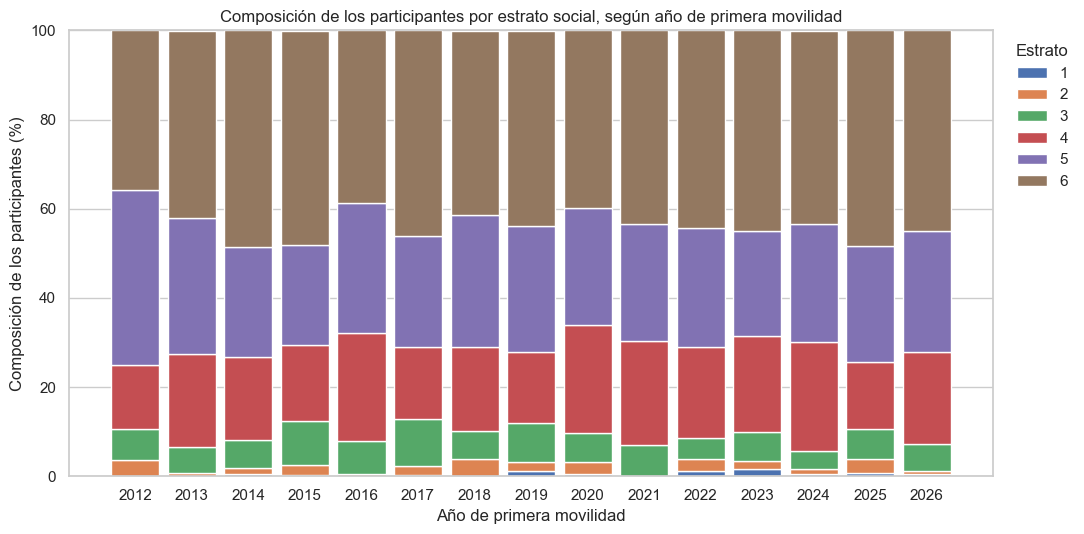

In [4]:
# Utilidad local: pivotear una serie de composición [{anio, <campo>, pct}] a una
# matriz año x categoría (rellenando 0 donde no hubo), igual que hace el dashboard.
def _pivot_composicion(serie, campo):
    d = pd.DataFrame(serie)
    piv = (d.pivot_table(index='anio', columns=campo, values='pct', aggfunc='sum')
             .sort_index())
    piv = piv.fillna(0.0)
    return piv

def _apilado_100(piv, titulo, etiqueta_leyenda, nombre_png):
    fig, ax = plt.subplots(figsize=(11, 5.5))
    base = np.zeros(len(piv))
    x = piv.index.astype(int)
    colores = sns.color_palette('deep', n_colors=piv.shape[1])
    for color, col in zip(colores, piv.columns):
        vals = piv[col].to_numpy()
        ax.bar(x, vals, bottom=base, label=str(col), color=color, width=0.85)
        base = base + vals
    ax.set_title(titulo)
    ax.set_xlabel('Año de primera movilidad')
    ax.set_ylabel('Composición de los participantes (%)')
    ax.set_ylim(0, 100)
    ax.set_xticks(list(x))
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title=etiqueta_leyenda, bbox_to_anchor=(1.01, 1), loc='upper left',
              frameon=False)
    plt.tight_layout()
    utils.save_fig(fig, nombre_png)
    plt.show()

# --- Figura 1: composición por estrato x año (caso guía) ---
piv_estrato = _pivot_composicion(hist['composicion_estrato'], 'estrato')
_apilado_100(piv_estrato,
             'Composición de los participantes por estrato social, según año de primera movilidad',
             'Estrato', 'fig_hist_estrato.png')

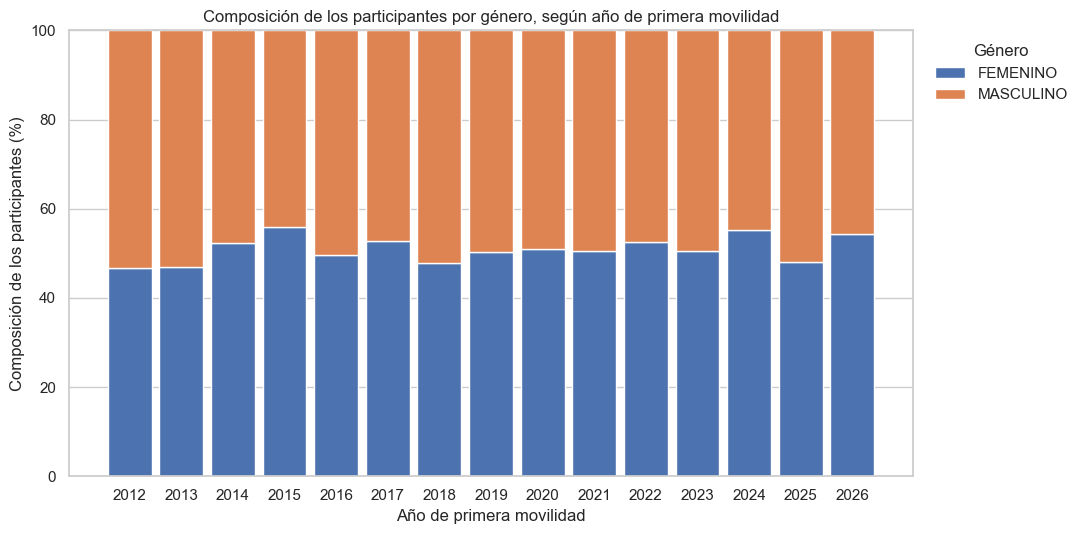

In [5]:
# --- Figura 2: composición por género x año ---
piv_genero = _pivot_composicion(hist['composicion_genero'], 'genero')
_apilado_100(piv_genero,
             'Composición de los participantes por género, según año de primera movilidad',
             'Género', 'fig_hist_genero.png')

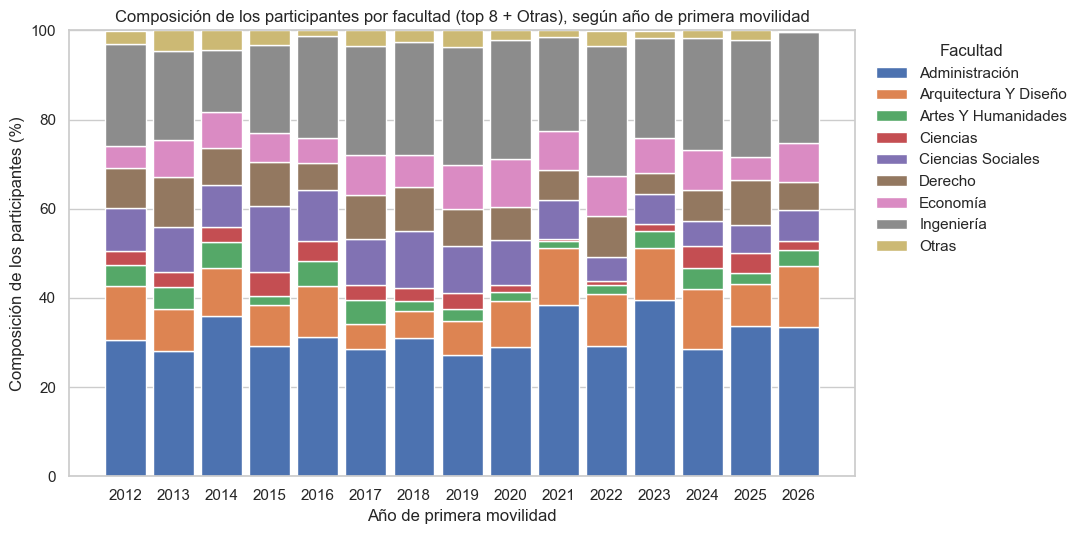

In [6]:
# --- Figura 3: composición por facultad x año (top 8 + Otras) ---
piv_facultad = _pivot_composicion(hist['composicion_facultad'], 'facultad')
_apilado_100(piv_facultad,
             'Composición de los participantes por facultad (top 8 + Otras), según año de primera movilidad',
             'Facultad', 'fig_hist_facultad.png')

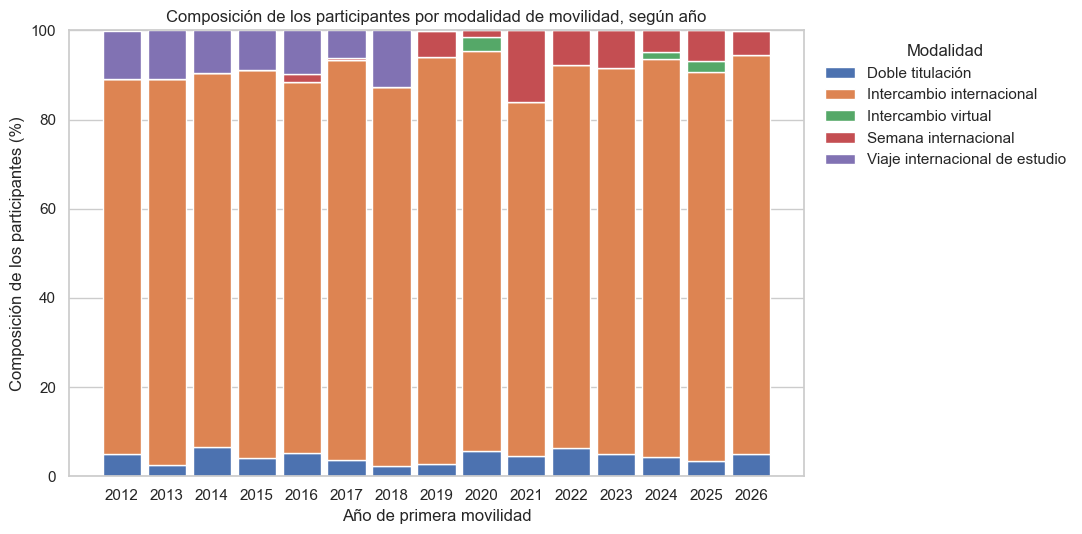

In [7]:
# --- Figura 4: composición por modalidad x año ---
piv_modalidad = _pivot_composicion(hist['composicion_modalidad'], 'modalidad')
_apilado_100(piv_modalidad,
             'Composición de los participantes por modalidad de movilidad, según año',
             'Modalidad', 'fig_hist_modalidad.png')

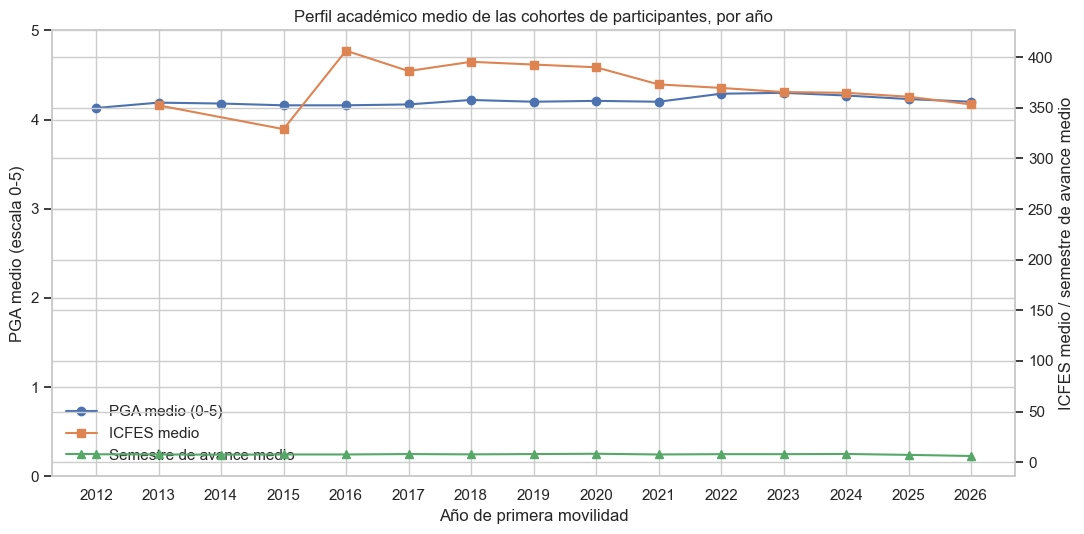

In [8]:
# --- Figura 5: evolución de las medias numéricas por año (perfil de cohorte) ---
# PGA en escala 0-5 (eje izquierdo); ICFES y avance en sus propias escalas
# (eje derecho). Solo se grafican las medias precalculadas en hist.
etiquetas_num = {'pga': 'PGA medio (0-5)', 'icfes': 'ICFES medio',
                 'avance': 'Semestre de avance medio'}
res = hist['resumen_numerico']

fig, ax_izq = plt.subplots(figsize=(11, 5.5))
ax_der = ax_izq.twinx()
colores = sns.color_palette('deep', 3)

# Eje izquierdo: PGA (escala acotada y distinta de las otras dos).
pga = pd.DataFrame(res['pga']).sort_values('anio')
l_pga, = ax_izq.plot(pga['anio'].astype(int), pga['media'], marker='o',
                     color=colores[0], label=etiquetas_num['pga'])
ax_izq.set_ylabel('PGA medio (escala 0-5)')
ax_izq.set_ylim(0, 5)

# Eje derecho: ICFES y avance (escalas mayores).
icfes = pd.DataFrame(res['icfes']).sort_values('anio')
avance = pd.DataFrame(res['avance']).sort_values('anio')
l_icfes, = ax_der.plot(icfes['anio'].astype(int), icfes['media'], marker='s',
                       color=colores[1], label=etiquetas_num['icfes'])
l_avance, = ax_der.plot(avance['anio'].astype(int), avance['media'], marker='^',
                        color=colores[2], label=etiquetas_num['avance'])
ax_der.set_ylabel('ICFES medio / semestre de avance medio')

ax_izq.set_xlabel('Año de primera movilidad')
ax_izq.set_title('Perfil académico medio de las cohortes de participantes, por año')
ax_izq.set_xticks(list(pga['anio'].astype(int)))
lineas = [l_pga, l_icfes, l_avance]
ax_izq.legend(lineas, [l.get_label() for l in lineas], loc='best', frameon=False)
plt.tight_layout()
utils.save_fig(fig, 'fig_hist_numericas.png')
plt.show()

### Interpretación
Las figuras apiladas muestran cómo ha cambiado el reparto interno de cada cohorte
anual de participantes (p.\,ej. la participación de los estratos más bajos dentro
del total de participantes de cada año), y la última figura resume el nivel
académico medio de esas cohortes. Son lecturas de **composición** y de **perfil
medio**: no indican qué proporción de cada grupo de la población participó.

## 3. Tablas (CSV + .tex booktabs)
Dos tablas, escritas como **CSV** en `reports/tables/` (fuente neutra, sin coma
decimal) y como **`.tex` booktabs/longtable** en `latex/tablas/` (lo que el informe
`\input`). La precisión por columna se deriva del **mismo** dict `hs.DECIMALES`
(fuente única de redondeo), keyed por clave de columna de la tabla (NIT-2).

In [9]:
# --- Tabla 1: composición por estrato x año (longtable: una fila por año-estrato) ---
df_estrato = pd.DataFrame(hist['composicion_estrato'])[['anio', 'estrato', 'n', 'pct']]
df_estrato = df_estrato.sort_values(['anio', 'estrato'], kind='mergesort').reset_index(drop=True)
df_estrato.to_csv(config.TABLES_DIR / 'historico_estrato.csv', index=False, encoding='utf-8')

cols_estrato = [
    ('anio', 'Año'), ('estrato', 'Estrato'), ('n', 'Participantes'), ('pct', '% del año'),
]
# decimales_por_col keyed por COLUMNA de la tabla, derivado de hs.DECIMALES.
dec_estrato = {'anio': None, 'estrato': None, 'n': None, 'pct': hs.DECIMALES['pct']}
# El año NO es una magnitud (sin separador de miles) -> string en el .tex.
df_estrato_tex = df_estrato.copy()
df_estrato_tex['anio'] = df_estrato_tex['anio'].astype(int).astype(str)
tex_estrato = df_to_latex_booktabs(
    df_estrato_tex, cols_estrato, dec_estrato, longtable=True,
    caption='Composición de los participantes por estrato social y año de primera movilidad (porcentaje dentro de cada año, participantes con dato de estrato).',
    label='tab:hist-estrato')
(LATEX_TABLAS / 'historico_estrato.tex').write_text(tex_estrato, encoding='utf-8')
print('historico_estrato: CSV + .tex OK (', len(df_estrato), 'filas )')

historico_estrato: CSV + .tex OK ( 84 filas )


In [10]:
# --- Tabla 2: resumen numérico por año (media/mediana/Q1/Q3 de PGA, ICFES, avance) ---
# Se arma una tabla ancha por año con la MEDIA de cada serie (el perfil medio de la
# cohorte). Las medias ya vienen redondeadas en hist; aquí solo se da formato.
def _media_por_anio(serie_rows):
    return {int(r['anio']): r['media'] for r in serie_rows}

m_pga = _media_por_anio(res['pga'])
m_icfes = _media_por_anio(res['icfes'])
m_avance = _media_por_anio(res['avance'])
n_por_anio = {int(r['anio']): int(r['n']) for r in meta['n_por_anio']}

filas_num = []
for a in anios:
    filas_num.append({
        'anio': int(a),
        'n': n_por_anio.get(int(a)),
        'pga_media': m_pga.get(int(a)),
        'icfes_media': m_icfes.get(int(a)),
        'avance_media': m_avance.get(int(a)),
    })
# CSV neutro: el año como entero sin separador de miles; faltantes como vacío.
df_num = pd.DataFrame(filas_num)
df_num.to_csv(config.TABLES_DIR / 'historico_numericas.csv', index=False, encoding='utf-8')

# Para el .tex: el año NO es una magnitud (sin separador de miles) -> string; los
# faltantes de media se dejan como None para que df_to_latex_booktabs imprima '---'
# en vez de 'nan'. Se construye una copia con dtype object que preserva None.
df_num_tex = pd.DataFrame([
    {
        'anio': str(f['anio']),
        'n': f['n'],
        'pga_media': None if f['pga_media'] is None else float(f['pga_media']),
        'icfes_media': None if f['icfes_media'] is None else float(f['icfes_media']),
        'avance_media': None if f['avance_media'] is None else float(f['avance_media']),
    }
    for f in filas_num
], dtype=object)

cols_num = [
    ('anio', 'Año'), ('n', 'Participantes'), ('pga_media', 'PGA medio'),
    ('icfes_media', 'ICFES medio'), ('avance_media', 'Avance medio'),
]
# Precisión por columna derivada de la 'media' de cada serie en hs.DECIMALES.
dec_num = {
    'anio': None,
    'n': None,
    'pga_media': hs.DECIMALES['numerico']['pga']['media'],
    'icfes_media': hs.DECIMALES['numerico']['icfes']['media'],
    'avance_media': hs.DECIMALES['numerico']['avance']['media'],
}
tex_num = df_to_latex_booktabs(
    df_num_tex, cols_num, dec_num, longtable=False,
    caption=None, label=None)
(LATEX_TABLAS / 'historico_numericas.tex').write_text(tex_num, encoding='utf-8')
print('historico_numericas: CSV + .tex OK (', len(df_num), 'filas )')

historico_numericas: CSV + .tex OK ( 15 filas )


## 4. Copia de figuras a `latex/figuras/`
El informe usa `\graphicspath{{figuras/}}`, por lo que las PNG deben estar en
`latex/figuras/`. Se copian desde `reports/figures/` con rutas absolutas.

In [11]:
for png in ['fig_hist_estrato.png', 'fig_hist_genero.png', 'fig_hist_facultad.png',
            'fig_hist_modalidad.png', 'fig_hist_numericas.png']:
    shutil.copy2(config.FIGURES_DIR / png, LATEX_FIG / png)
    print('copiada ->', (LATEX_FIG / png).name)

copiada -> fig_hist_estrato.png
copiada -> fig_hist_genero.png
copiada -> fig_hist_facultad.png
copiada -> fig_hist_modalidad.png
copiada -> fig_hist_numericas.png


## 5. Narrativa (encuadre explícito)
La prosa que acompaña al informe se redacta con el encuadre obligatorio:
composición de participantes por año (no proporción de participación por grupo),
perfil académico medio de cohortes, asociación no causa, y la limitación de que los
no participantes no tienen año asignado. La nota de encuadre proviene de la fuente
única (`hist['meta']['nota_framing']`), de modo que web e informe cuentan lo mismo.

In [12]:
def _escapar_tex(texto):
    '''Escapa % & # $ _ para LaTeX sin alterar las cifras.'''
    for k, v in (('&', r'\&'), ('%', r'\%'), ('#', r'\#'),
                 ('$', r'\$'), ('_', r'\_')):
        texto = texto.replace(k, v)
    return texto

nota = meta['nota_framing']
tex_nota = (
    "% Nota de encuadre del histórico, interpolada desde historical_stats: NO editar a mano.\n"
    + _escapar_tex(nota) + "\n"
)
(LATEX_TABLAS / 'historico_narrativa.tex').write_text(tex_nota, encoding='utf-8')
print('historico_narrativa.tex escrita. Longitud:', len(nota), 'caracteres.')
print('\n' + nota)

historico_narrativa.tex escrita. Longitud: 326 caracteres.

Composición de los participantes de cada año y perfil académico medio de esas cohortes (no es proporción de participación por grupo: los no participantes no tienen año asignado). La composición por estrato/género se calcula sobre los participantes CON dato de la dimensión; 'Sin dato' se excluye y cada año renormaliza a 100%.


## 6. Verificación de consistencia (M1)
Esta celda **falla el build** (`python build_notebooks.py 07`) si las cifras que el
informe REALMENTE renderiza divergen de la fuente única. Compara, a la precisión
publicada (`hs.DECIMALES`), dos cantidades entre **tres orígenes** ---`hist`
(cálculo), `data.json` clave `historico` (web) y el **CSV renderizado** del
informe---:

1. una serie de **composición**: `pct` del estrato de un año fijo,
2. una serie **numérica**: media de **PGA** de un año fijo.

No se limita a comparar `data.json` contra `compute_historical`: incluye el
artefacto que el informe imprime, que es lo que el lector ve.

In [13]:
def _r_pct(v):
    return None if v is None else round(float(v), hs.DECIMALES['pct'])

def _r_pga(v):
    return None if v is None else round(float(v), hs.DECIMALES['numerico']['pga']['media'])

# Año fijo y categoría fija para el contraste (deterministas: primer año con la
# categoría de estrato de mayor pct ese año, para no depender de un valor concreto).
anio_fijo = int(anios[0])

# (1) Desde hist (cálculo).
estrato_hist = [r for r in hist['composicion_estrato'] if int(r['anio']) == anio_fijo]
assert estrato_hist, f'No hay composición de estrato para el año {anio_fijo} en hist.'
estrato_hist = sorted(estrato_hist, key=lambda r: str(r['estrato']))[0]
estrato_fijo = str(estrato_hist['estrato'])
pga_hist = [r for r in hist['resumen_numerico']['pga'] if int(r['anio']) == anio_fijo][0]

# (2) Desde data.json (lo que consume la web).
data_json = json.loads(DATA_JSON.read_text(encoding='utf-8'))
hj = data_json['historico']
estrato_json = [r for r in hj['composicion_estrato']
                if int(r['anio']) == anio_fijo and str(r['estrato']) == estrato_fijo][0]
pga_json = [r for r in hj['resumen_numerico']['pga'] if int(r['anio']) == anio_fijo][0]

# (3) Desde el CSV renderizado (fuente directa del .tex del informe).
with open(config.TABLES_DIR / 'historico_estrato.csv', encoding='utf-8') as fh:
    filas_csv_estrato = list(csv.DictReader(fh))
estrato_csv = [r for r in filas_csv_estrato
               if int(r['anio']) == anio_fijo and str(r['estrato']) == estrato_fijo][0]
with open(config.TABLES_DIR / 'historico_numericas.csv', encoding='utf-8') as fh:
    filas_csv_num = list(csv.DictReader(fh))
pga_csv = [r for r in filas_csv_num if int(r['anio']) == anio_fijo][0]

# --- Aserción composición: pct de estrato (hist == json == csv) ---
p_hist = _r_pct(estrato_hist['pct'])
p_json = _r_pct(estrato_json['pct'])
p_csv = _r_pct(float(estrato_csv['pct']))
assert p_hist == p_json == p_csv, \
    f'Inconsistencia pct estrato {estrato_fijo} año {anio_fijo}: hist={p_hist} json={p_json} csv={p_csv}'

# --- Aserción numérica: media de PGA (hist == json == csv) ---
g_hist = _r_pga(pga_hist['media'])
g_json = _r_pga(pga_json['media'])
g_csv = _r_pga(float(pga_csv['pga_media']))
assert g_hist == g_json == g_csv, \
    f'Inconsistencia media PGA año {anio_fijo}: hist={g_hist} json={g_json} csv={g_csv}'

print(f'[M1] Consistencia verificada sobre lo que el informe RENDERIZA (hist == data.json == CSV/.tex):')
print(f'  Composición estrato {estrato_fijo} (año {anio_fijo}) = {p_hist}%')
print(f'  PGA medio (año {anio_fijo})                         = {g_hist}')
print('[M1] OK — ninguna divergencia.')

[M1] Consistencia verificada sobre lo que el informe RENDERIZA (hist == data.json == CSV/.tex):


  Composición estrato 2 (año 2012) = 3.6%
  PGA medio (año 2012)                         = 4.13
[M1] OK — ninguna divergencia.


### Cierre
Con esta celda en verde, los artefactos del histórico quedan garantizados como
coherentes con el dashboard: misma fuente de cálculo, mismo redondeo y las cifras
críticas verificadas sobre el CSV/.tex que el informe efectivamente imprime. Si en
el futuro alguien cambiara el cálculo sin regenerar los artefactos, este notebook
fallaría y detendría el build, protegiendo la consistencia web↔informe (RNF-1).